# 03 — Analisis Data Eksploratif: Gambaran Nasional

**Pertanyaan:** Bagaimana tren kualitas udara (IKU) Indonesia 2020–2024, provinsi mana yang terbaik/terburuk, wilayah mana yang tertinggal, dan bagaimana kaitannya dengan kepadatan penduduk?

> IKU berskala 0–100; **makin tinggi makin baik**. IKU disusun dari parameter NO₂ dan SO₂.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

mpl.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)

master = pd.read_csv(PROC / "provinsi_master.csv")
iku_city = pd.read_csv(PROC / "iku_kabkota_long.csv")

prov = master[master["provinsi"] != "INDONESIA"].copy()
nasional = master[master["provinsi"] == "INDONESIA"].copy()
print("Master:", master.shape, "| provinsi (tanpa Indonesia):", prov["provinsi"].nunique())
print("Tahun:", sorted(master['tahun'].unique()))

Master: (195, 6) | provinsi (tanpa Indonesia): 38
Tahun: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


## 1. Tren nasional 2020–2024

 tahun       iku      iklh
  2020 88.270588 71.023529
  2021 88.444118 72.237647
  2022 89.197059 73.074706
  2023 90.242105 74.167368
  2024 91.325789 75.111842

Perubahan IKU nasional 2020->2024: +3.06 poin


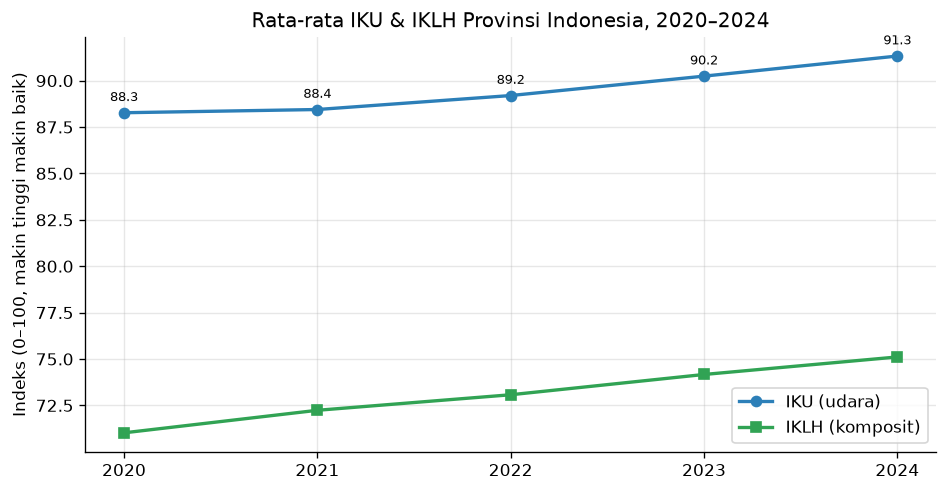

In [2]:
nas = prov.groupby("tahun").agg(iku=("iku", "mean"), iklh=("iklh", "mean")).reset_index()
print(nas.to_string(index=False))
d_iku = nas.loc[nas.tahun == 2024, "iku"].values[0] - nas.loc[nas.tahun == 2020, "iku"].values[0]
print(f"\nPerubahan IKU nasional 2020->2024: {d_iku:+.2f} poin")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(nas["tahun"], nas["iku"], marker="o", lw=2, color="#2c7fb8", label="IKU (udara)")
ax.plot(nas["tahun"], nas["iklh"], marker="s", lw=2, color="#31a354", label="IKLH (komposit)")
for _, r in nas.iterrows():
    ax.annotate(f"{r['iku']:.1f}", (r["tahun"], r["iku"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_title("Rata-rata IKU & IKLH Provinsi Indonesia, 2020–2024")
ax.set_ylabel("Indeks (0–100, makin tinggi makin baik)")
ax.set_xticks(nas["tahun"])
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(IMG / "03_tren_nasional.png"); plt.show()

## 2. Peringkat provinsi (IKU 2024)

10 TERBAIK
          provinsi    wilayah   iku
KALIMANTAN SELATAN Kalimantan 96.41
      PAPUA TENGAH      Papua 96.00
  PAPUA BARAT DAYA      Papua 95.79
             PAPUA      Papua 95.17
     PAPUA SELATAN      Papua 94.86
       PAPUA BARAT      Papua 94.40
          BENGKULU   Sumatera 94.13
      MALUKU UTARA     Maluku 93.88
 SULAWESI TENGGARA   Sulawesi 93.83
  PAPUA PEGUNUNGAN      Papua 93.81

10 TERBURUK
        provinsi    wilayah   iku
KALIMANTAN TIMUR Kalimantan 91.43
         LAMPUNG   Sumatera 90.94
   DI YOGYAKARTA       Jawa 90.44
SUMATERA SELATAN   Sumatera 90.25
            RIAU   Sumatera 89.66
      JAWA TIMUR       Jawa 88.09
     JAWA TENGAH       Jawa 87.73
      JAWA BARAT       Jawa 83.68
     DKI JAKARTA       Jawa 72.59
          BANTEN       Jawa 69.84

Rata-rata 2024: 91.33 | median: 92.72 | std: 5.37


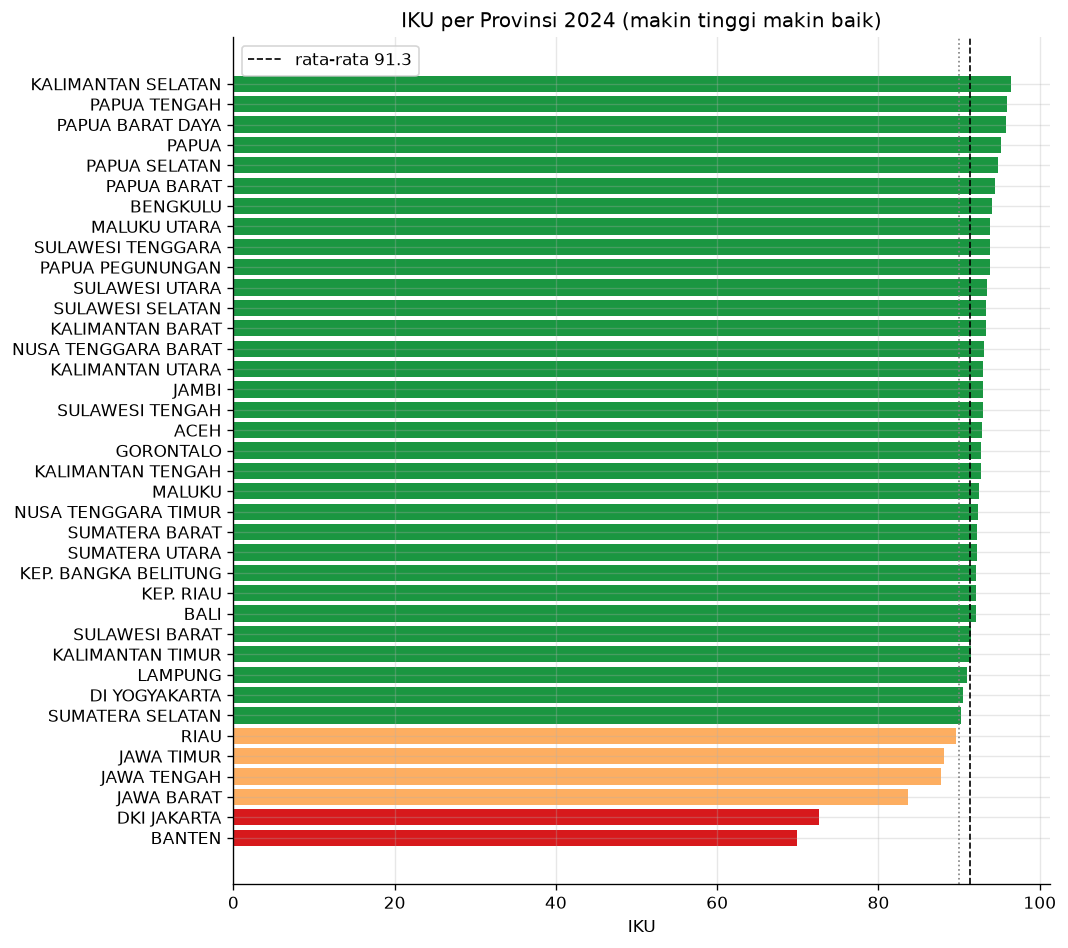

In [3]:
iku24 = prov[prov["tahun"] == 2024].sort_values("iku", ascending=False).reset_index(drop=True)
print("10 TERBAIK"); print(iku24.head(10)[["provinsi", "wilayah", "iku"]].to_string(index=False))
print("\n10 TERBURUK"); print(iku24.tail(10)[["provinsi", "wilayah", "iku"]].to_string(index=False))
print(f"\nRata-rata 2024: {iku24['iku'].mean():.2f} | median: {iku24['iku'].median():.2f} | std: {iku24['iku'].std():.2f}")

fig, ax = plt.subplots(figsize=(9, 8))
d = iku24.sort_values("iku")
colors = d["iku"].map(lambda v: "#d7191c" if v < 80 else ("#fdae61" if v < 90 else "#1a9641"))
ax.barh(d["provinsi"], d["iku"], color=colors)
ax.axvline(iku24["iku"].mean(), color="k", ls="--", lw=1, label=f"rata-rata {iku24['iku'].mean():.1f}")
ax.axvline(90, color="gray", ls=":", lw=1)
ax.set_title("IKU per Provinsi 2024 (makin tinggi makin baik)")
ax.set_xlabel("IKU"); ax.legend()
fig.tight_layout(); fig.savefig(IMG / "03_peringkat_provinsi_2024.png"); plt.show()

## 3. IKU per wilayah (boxplot 2024)

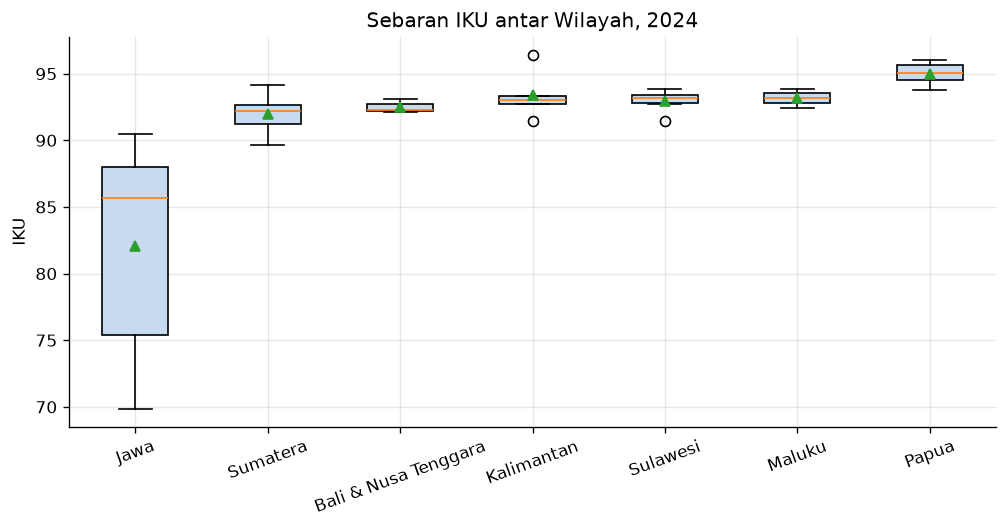

                       mean    min    max  count
wilayah                                         
Jawa                  82.06  69.84  90.44      6
Sumatera              91.96  89.66  94.13     10
Bali & Nusa Tenggara  92.52  92.12  93.13      3
Sulawesi              92.96  91.46  93.83      6
Maluku                93.15  92.42  93.88      2
Kalimantan            93.37  91.43  96.41      5
Papua                 95.00  93.81  96.00      6


In [4]:
order = iku24.groupby("wilayah")["iku"].median().sort_values().index.tolist()
data = [iku24.loc[iku24.wilayah == w, "iku"].values for w in order]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bp = ax.boxplot(data, tick_labels=order, patch_artist=True, showmeans=True)
for b in bp["boxes"]:
    b.set_facecolor("#c6dbef")
ax.set_title("Sebaran IKU antar Wilayah, 2024")
ax.set_ylabel("IKU"); ax.tick_params(axis="x", rotation=20)
fig.tight_layout(); fig.savefig(IMG / "03_iku_per_wilayah.png"); plt.show()
print(iku24.groupby("wilayah")["iku"].agg(["mean", "min", "max", "count"]).round(2).sort_values("mean").to_string())

## 4. Perubahan 2020 → 2024 (siapa membaik/memburuk)

PENURUNAN terbesar (memburuk):
        provinsi    wilayah  2020  2024  delta
          BANTEN       Jawa  72.8 69.84  -2.96
KALIMANTAN UTARA Kalimantan  94.2 92.99  -1.21
       GORONTALO   Sulawesi  93.9 92.73  -1.17
            RIAU   Sumatera  90.4 89.66  -0.74
     PAPUA BARAT      Papua  94.8 94.40  -0.40
           PAPUA      Papua  94.6 95.17   0.57

KENAIKAN terbesar (membaik):
          provinsi    wilayah  2020  2024  delta
  SULAWESI SELATAN   Sulawesi  88.7 93.36   4.66
        JAWA BARAT       Jawa  78.5 83.68   5.18
           LAMPUNG   Sumatera  85.5 90.94   5.44
       DKI JAKARTA       Jawa  66.7 72.59   5.89
             JAMBI   Sumatera  85.7 92.98   7.28
KALIMANTAN SELATAN Kalimantan  88.9 96.41   7.51


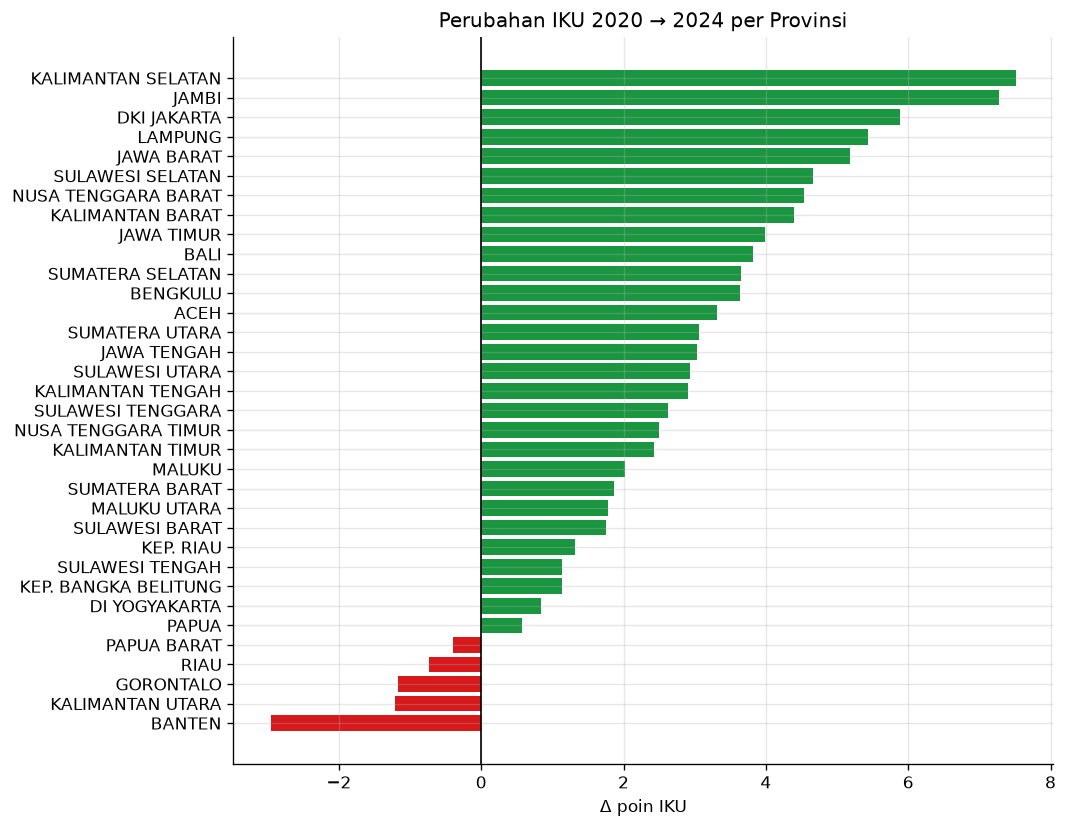

In [5]:
piv = prov.pivot_table(index=["provinsi", "wilayah"], columns="tahun", values="iku")
piv["delta"] = piv[2024] - piv[2020]
delta = piv.dropna(subset=["delta"]).reset_index().sort_values("delta")
print("PENURUNAN terbesar (memburuk):"); print(delta.head(6)[["provinsi", "wilayah", 2020, 2024, "delta"]].round(2).to_string(index=False))
print("\nKENAIKAN terbesar (membaik):"); print(delta.tail(6)[["provinsi", "wilayah", 2020, 2024, "delta"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 7))
d = delta.sort_values("delta")
ax.barh(d["provinsi"], d["delta"], color=np.where(d["delta"] < 0, "#d7191c", "#1a9641"))
ax.axvline(0, color="k", lw=1)
ax.set_title("Perubahan IKU 2020 → 2024 per Provinsi")
ax.set_xlabel("Δ poin IKU"); 
fig.tight_layout(); fig.savefig(IMG / "03_delta_iku.png"); plt.show()

## 5. Kepadatan penduduk vs IKU (2024)

Korelasi, **bukan** kausalitas. Hanya 34 provinsi lama yang punya data kepadatan (2021).

n = 34 | Pearson r = -0.666 (p=0.000) | Spearman rho = -0.583


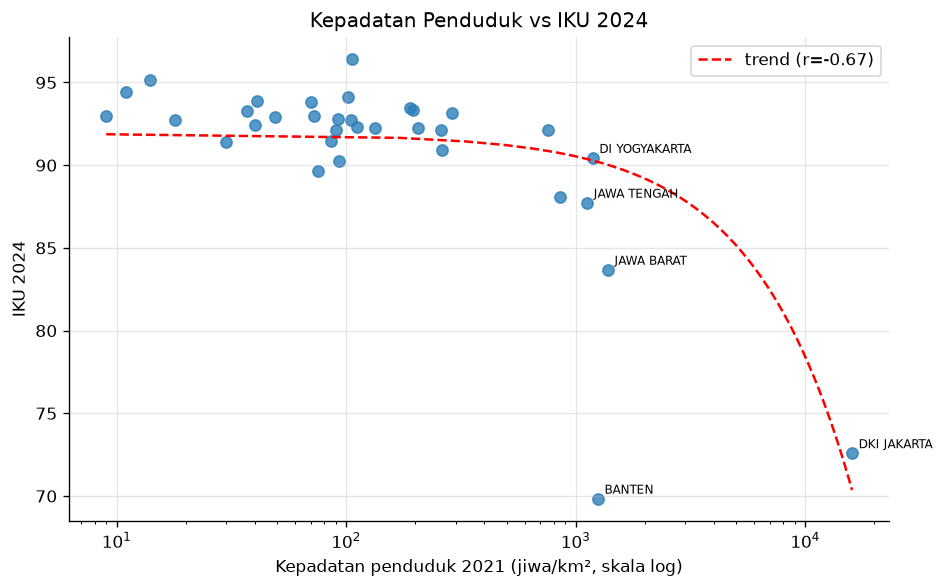

In [6]:
sc = iku24.dropna(subset=["kepadatan_penduduk_2021"]).copy()
pear = stats.pearsonr(sc["kepadatan_penduduk_2021"], sc["iku"])
spear = stats.spearmanr(sc["kepadatan_penduduk_2021"], sc["iku"])
print(f"n = {len(sc)} | Pearson r = {pear.statistic:.3f} (p={pear.pvalue:.3f}) | Spearman rho = {spear.statistic:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sc["kepadatan_penduduk_2021"], sc["iku"], s=45, color="#2c7fb8", alpha=0.8)
for _, r in sc.iterrows():
    if r["iku"] < 80 or r["kepadatan_penduduk_2021"] > 1000:
        ax.annotate(r["provinsi"], (r["kepadatan_penduduk_2021"], r["iku"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
z = np.polyfit(sc["kepadatan_penduduk_2021"], sc["iku"], 1)
xs = np.linspace(sc["kepadatan_penduduk_2021"].min(), sc["kepadatan_penduduk_2021"].max(), 100)
ax.plot(xs, np.polyval(z, xs), "r--", lw=1.5, label=f"trend (r={pear.statistic:.2f})")
ax.set_xscale("log")
ax.set_xlabel("Kepadatan penduduk 2021 (jiwa/km², skala log)")
ax.set_ylabel("IKU 2024"); ax.legend()
ax.set_title("Kepadatan Penduduk vs IKU 2024")
fig.tight_layout(); fig.savefig(IMG / "03_kepadatan_vs_iku.png"); plt.show()

## 6. Heatmap IKU provinsi × tahun

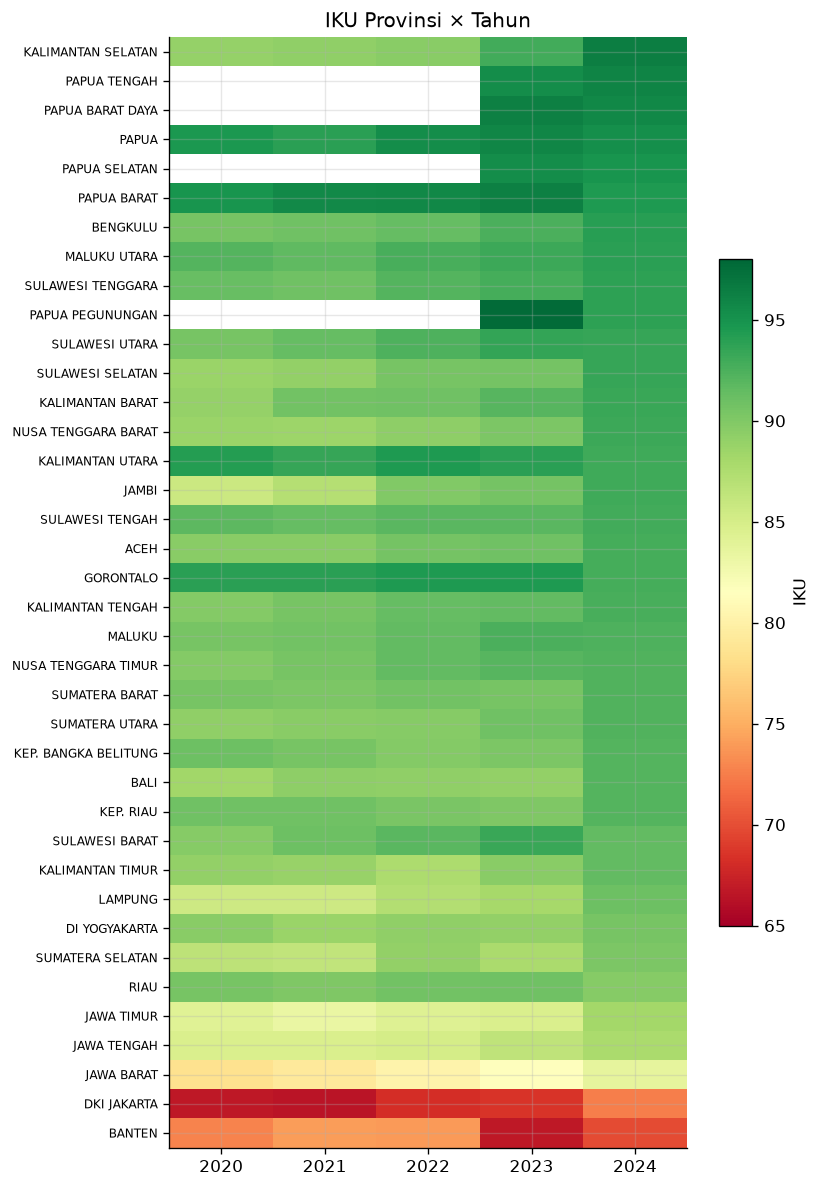

Gambar tersimpan di: C:\Voicegame\analisis-kualitas-udara-indonesia\images
  03_delta_iku.png
  03_heatmap_iku.png
  03_iku_per_wilayah.png
  03_kepadatan_vs_iku.png
  03_peringkat_provinsi_2024.png
  03_tren_nasional.png


In [7]:
hm = prov.pivot_table(index="provinsi", columns="tahun", values="iku").sort_values(2024, ascending=False)
fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(hm.values, aspect="auto", cmap="RdYlGn", vmin=65, vmax=98)
ax.set_xticks(range(len(hm.columns)), hm.columns)
ax.set_yticks(range(len(hm.index)), hm.index, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.6, label="IKU")
ax.set_title("IKU Provinsi × Tahun")
fig.tight_layout(); fig.savefig(IMG / "03_heatmap_iku.png"); plt.show()

print("Gambar tersimpan di:", IMG)
for f in sorted(IMG.glob("03_*.png")):
    print(" ", f.name)

## Catatan analisis
- Nilai provinsi baru (Papua Selatan/Tengah/Pegunungan, Papua Barat Daya) kosong untuk 2020–2022 → dikecualikan pada perhitungan Δ 2020→2024.
- Korelasi kepadatan–IKU dihitung pada 2024 saja dan hanya provinsi lama.
- Semua angka berasal dari tabel KLHK/BPS; tidak ada nilai yang dikarang.